# 03 · Time from cart to purchase (Kaplan–Meier)
Unit: a user's first cart of a product. Event: that user buys that product within 7 days, in any
session. Carts are censored at 7 days or at the end of the data (2019-11-01), whichever is first.
Curves are split by price tier and by first-time vs returning buyer (a purchase earlier in October).

In [1]:
import json, os
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = os.environ.get("FUNNEL_DB", ROOT / "data/processed/funnel.duckdb")
FIG = ROOT / "outputs/figures"
RESULTS = ROOT / "outputs/results.json"
con = duckdb.connect(str(DB), read_only=True)
results = json.loads(RESULTS.read_text())
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
TIERS = {1: "Q1 budget", 2: "Q2", 3: "Q3", 4: "Q4 premium"}
HORIZON_H = 7 * 24

In [2]:
carts = con.sql(f"""
WITH c AS (
    SELECT user_id, product_id, min(event_time) AS cart_time, arg_min(price, event_time) AS cart_price
    FROM events_s WHERE event_type = 'cart' GROUP BY ALL
), p AS (
    SELECT c.user_id, c.product_id, c.cart_time, c.cart_price, min(e.event_time) AS purchase_time
    FROM c LEFT JOIN events_s e
      ON e.user_id = c.user_id AND e.product_id = c.product_id
     AND e.event_type = 'purchase' AND e.event_time >= c.cart_time
    GROUP BY ALL
)
SELECT p.*, t.category, t.price_tier,
    coalesce(u.first_purchase_time < p.cart_time, false) AS is_returning,
    least({HORIZON_H}, (epoch(TIMESTAMP '2019-11-01') - epoch(cart_time)) / 3600) AS max_follow_h,
    (epoch(purchase_time) - epoch(cart_time)) / 3600 AS to_purchase_h
FROM p JOIN product_tiers t USING (product_id) LEFT JOIN user_first_purchase u USING (user_id)
""").df()
carts["event"] = carts.to_purchase_h.notna() & (carts.to_purchase_h <= carts.max_follow_h)
carts["duration_h"] = carts.to_purchase_h.where(carts.event, carts.max_follow_h).clip(lower=1 / 3600)
carts["tier"] = carts.price_tier.map(TIERS)
carts["buyer"] = np.where(carts.is_returning, "Returning", "First-time")
print(f"{len(carts):,} first carts, {carts.event.mean():.1%} bought within follow-up")

50,113 first carts, 51.4% bought within follow-up


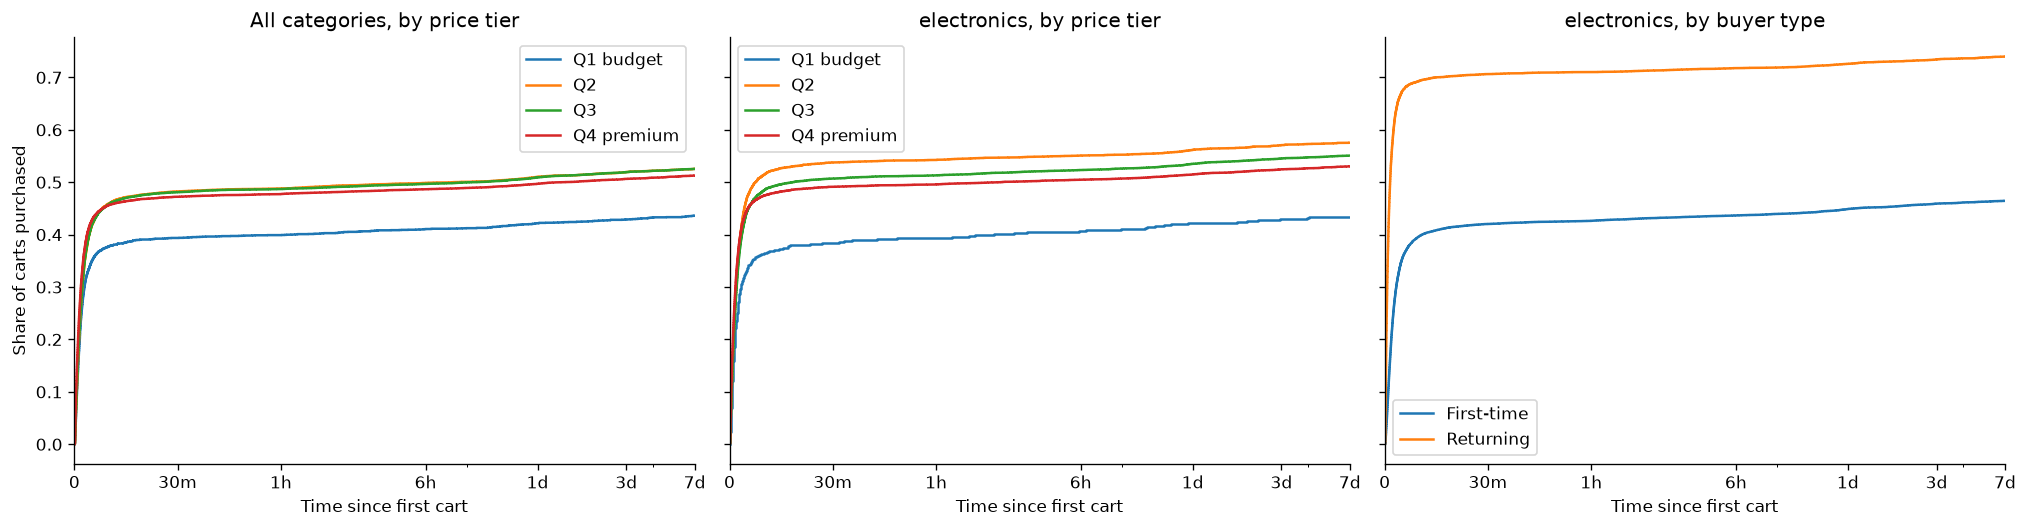

,group,split,level,n,bought_by_0.5h,bought_by_24h,bought_by_168h
0,All categories,tier,Q1 budget,3696,0.3937,0.4216,0.4363
1,All categories,tier,Q2,12147,0.4824,0.5103,0.5257
2,All categories,tier,Q3,18377,0.4809,0.5093,0.5254
3,All categories,tier,Q4 premium,15893,0.4723,0.4969,0.5128
4,electronics,tier,Q1 budget,1242,0.3841,0.4221,0.4331
5,electronics,tier,Q2,6940,0.5378,0.5617,0.5754
6,electronics,tier,Q3,14116,0.5069,0.5351,0.5508
7,electronics,tier,Q4 premium,13269,0.4914,0.5148,0.5304
8,electronics,buyer,First-time,25306,0.4203,0.4488,0.4645
9,electronics,buyer,Returning,10261,0.7064,0.7259,0.7398


In [3]:
target_cat = results["customer_split"]["category"]
checkpoints = [0.5, 24, HORIZON_H]
km_rows = []
elec = carts[carts.category == target_cat]
panels = [("All categories", carts, "tier"), (target_cat, elec, "tier"), (target_cat, elec, "buyer")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (name, df, split) in zip(axes, panels):
    for level, g in df.groupby(split):
        kmf = KaplanMeierFitter(label=level).fit(g.duration_h, g.event)
        (1 - kmf.survival_function_).plot(ax=ax, drawstyle="steps-post")
        km_rows.append({"group": name, "split": split, "level": level, "n": len(g),
                        **{f"bought_by_{h}h": round(1 - kmf.predict(h), 4) for h in checkpoints}})
    ax.set_xscale("symlog", linthresh=1); ax.set_xlim(0, HORIZON_H)
    ax.set_xticks([0, 0.5, 1, 6, 24, 72, 168], ["0", "30m", "1h", "6h", "1d", "3d", "7d"])
    ax.set_title(f"{name}, by {'price tier' if split == 'tier' else 'buyer type'}"); ax.set_xlabel("Time since first cart")
axes[0].set_ylabel("Share of carts purchased")
fig.tight_layout(); fig.savefig(FIG / "survival_by_tier.png"); plt.show()
km = pd.DataFrame(km_rows)
km

In [4]:
lr_tier = multivariate_logrank_test(elec.duration_h, elec.tier, elec.event)
lr_buyer = multivariate_logrank_test(elec.duration_h, elec.buyer, elec.event)
buyers = carts[carts.event]
secs = buyers.to_purchase_h * 3600
first_time = elec[~elec.is_returning]
results["survival"] = {
    "n_first_carts": len(carts),
    "km": km.to_dict("records"),
    "logrank_p_tier_target": lr_tier.p_value, "logrank_p_buyer_target": lr_buyer.p_value,
    "share_of_7d_purchases_within_10s": round((secs <= 10).mean(), 4),
    "share_of_7d_purchases_within_5m": round((secs <= 300).mean(), 4),
    "share_of_7d_purchases_within_30m": round((secs <= 1800).mean(), 4),
    "share_of_7d_purchases_after_24h": round((buyers.to_purchase_h > 24).mean(), 4),
    "median_minutes_to_purchase_buyers": round(60 * buyers.to_purchase_h.median(), 2),
    "target": {"category": target_cat, "buyer": "First-time", "n_first_carts_sample": len(first_time),
               "avg_cart_price": round(first_time.cart_price.mean(), 2),
               "p0_7day": km.query("group == @target_cat and level == 'First-time'").bought_by_168h.iloc[0]},
}
print(f"{target_cat} log-rank p: by tier {lr_tier.p_value:.2g}, by buyer type {lr_buyer.p_value:.2g}")
print({k: v for k, v in results["survival"].items() if k != "km"})

electronics log-rank p: by tier 6.2e-17, by buyer type 0
{'n_first_carts': 50113, 'logrank_p_tier_target': np.float64(6.194769651856876e-17), 'logrank_p_buyer_target': np.float64(0.0), 'share_of_7d_purchases_within_10s': np.float64(0.0064), 'share_of_7d_purchases_within_5m': np.float64(0.8064), 'share_of_7d_purchases_within_30m': np.float64(0.9187), 'share_of_7d_purchases_after_24h': np.float64(0.0289), 'median_minutes_to_purchase_buyers': np.float64(1.75), 'target': {'category': 'electronics', 'buyer': 'First-time', 'n_first_carts_sample': 25306, 'avg_cart_price': np.float64(398.47), 'p0_7day': np.float64(0.4645)}}


In [5]:
RESULTS.write_text(json.dumps(results, indent=2, default=float))

6618